# 📊 Trực quan hóa Dữ liệu (EDA & Visualization)

---

🎯 **Mục tiêu**

Khám phá và trực quan hóa các đặc trưng chính của dataset tương tác AI, cung cấp góc nhìn đa chiều về hành vi sử dụng và xu hướng phát triển qua thời gian.

1. **Xu hướng Tăng trưởng theo Năm:** Khảo sát sự dịch chuyển quy mô dữ liệu qua từng năm, làm nổi bật giai đoạn bùng nổ của các công cụ AI.
2. **Tỷ lệ Ngôn ngữ Lập trình:** Thống kê thị phần và so sánh tương quan giữa `python` và `js` trong toàn bộ dataset.
3. **Phân bố theo Thời gian (Giờ & Thứ):** Phân tích khung giờ cao điểm và ngày trong tuần (`0 - 23 UTC+0`) khi người dùng tương tác nhiều nhất.

💡

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import seaborn as sns

from parso.python.tokenize import group

warnings.filterwarnings('ignore')

try:
    import missingno as msno
    HAS_MSNO = True
except ImportError:
    HAS_MSNO = False

DATA_PATH = r"..\data\processed\cleaned_commits_data_final.csv"
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"✅ Đã tải dữ liệu: {df_raw.shape[0]:,} hàng × {df_raw.shape[1]} cột")

✅ Đã tải dữ liệu: 34,075 hàng × 10 cột


---
# BLOCK 1 — Khảo sát số lượng và sự tăng trưởng theo năm theo năm
---

449                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

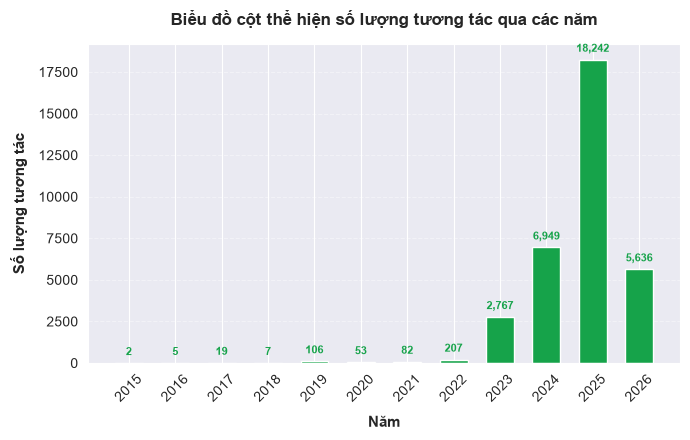

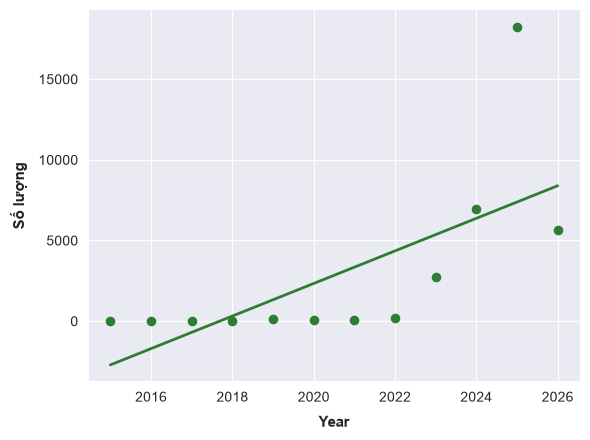

In [44]:
df_raw["commit_date"]= pd.to_datetime(df_raw["commit_date"])
df_raw['Year'] = df_raw["commit_date"].dt.year.astype('Int64')
df_raw['Hour'] = df_raw["commit_date"].dt.hour.astype('Int64')
df_raw['Day_of_Week'] = df_raw['commit_date'].dt.day_name()

df_2015 = df_raw[df_raw["Year"] == 2017]
pd.set_option('display.max_colwidth', None)
# In ra 10 dòng đầu tiên của dữ liệu đã lọc
print(df_2015["code_block"].head(10))


year_counting = df_raw.groupby("Year", as_index=False).size()
year_count = pd.DataFrame({
    'Năm' : year_counting["Year"],
    'Số lượng': year_counting["size"],
    'Tỉ lệ (%)': (year_counting["size"]/len(df_raw)*100).round(2)
})


#PillarChart-------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(
    year_count['Năm'],
    year_count['Số lượng'],
    color='#16a34a',
    width=0.6,
    zorder=2
)
# Gắn giá trị cụ thể lên đỉnh tất cả các cột
for bar in bars:
    height = bar.get_height()
    if height > 0:  # Chỉ hiển thị số với các cột có giá trị lớn hơn 0 để tránh rối
        ax.annotate(
            f'{height:,}',
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),  # Khoảng cách từ đỉnh cột lên chữ
            textcoords="offset points",
            ha='center', va='bottom',
            fontsize=8, fontweight='bold', color='#16a34a'
        )

ax.set_xlabel("Năm", fontsize=11, fontweight='bold', labelpad=8)
ax.set_ylabel("Số lượng tương tác", fontsize=11, fontweight='bold', labelpad=8)
ax.set_title("Biểu đồ cột thể hiện số lượng tương tác qua các năm", fontsize=12, fontweight='bold', pad=14)

# Bật lưới ngang mờ để dễ gióng giá trị
ax.grid(axis='y', linestyle='--', alpha=0.4, zorder=1)

# Hiển thị đầy đủ các năm trên trục X
plt.xticks(year_count['Năm'], rotation=45)
plt.tight_layout()
plt.show()




#ScatterPlot------------------------------------
x = year_count['Năm']
y = year_count['Số lượng']
fig, ax = plt.subplots(figsize=(6, 4.5))

# 1. Tính toán đường xu hướng tuyến tính (Linear Regression)
m, b = np.polyfit(x, y, 1)  # m là hệ số góc, b là hệ số tự do
# 2. Vẽ đường xu hướng (Trendline) màu xanh lá
ax.plot(x, m*x + b, color='#2e7d32', linewidth=2, label='Xu hướng', zorder=2)
# 3. Vẽ các điểm Scatter plot màu xanh lá
ax.scatter(x, y, color='#2e7d32', s=35, zorder=3)


# Bỏ khung phía trên và bên phải
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Làm đậm trục X và Y bên trái/dưới
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

# Đặt nhãn tên trục và tiêu đề
ax.set_xlabel("Year", fontsize=11, fontweight='bold', labelpad=8)
ax.set_ylabel("Số lượng", fontsize=11, fontweight='bold', labelpad=8)

plt.tight_layout()
plt.show()

---
# BLOCK 2 — Trực quan hóa tỷ lệ và số lượng ngôn ngữ lập trình
---

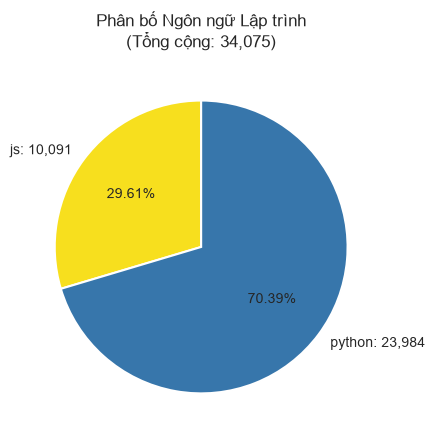

In [45]:
lauguage_counting = df_raw.groupby("language", as_index=False).size()
language_count = pd.DataFrame({
    'Ngôn ngữ': lauguage_counting["language"],
    'Số lượng': lauguage_counting["size"],
    'Tỉ lệ (%)': (lauguage_counting["size"]/len(df_raw)*100).round(2)
})

color_map = {
    'js': '#F7DF1E',
    'python': '#3776AB'
}
colors = [color_map.get(str(lang).lower(), '#999999') for lang in language_count['Ngôn ngữ']]

total_samples = language_count['Số lượng'].sum()

fig, ax = plt.subplots(figsize=(4.5, 4.5))

# Nhãn tên ngôn ngữ kết hợp số lượng ở bên ngoài
external_labels = [
    f"{row['Ngôn ngữ']}: {row['Số lượng']:,}"
    for _, row in language_count.iterrows()
]

# Lấy trực tiếp danh sách tỷ lệ % có sẵn từ DataFrame để hiển thị vào trong lát cắt
percentages = language_count['Tỉ lệ (%)'].tolist()
autopct_func = lambda pct: f"{percentages.pop(0):.2f}%"

ax.pie(
    language_count['Số lượng'],
    labels=external_labels,
    autopct=autopct_func,
    startangle=90,
    colors=colors,
    pctdistance=0.6,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)

# Tiêu đề kèm tổng số mẫu
ax.set_title(
    f"Phân bố Ngôn ngữ Lập trình\n(Tổng cộng: {total_samples:,})",
    pad=12
)

plt.tight_layout()
plt.show()

---
# BLOCK 3 — Trực quan hóa Phân bố theo Thời gian (Giờ & Thứ)
---

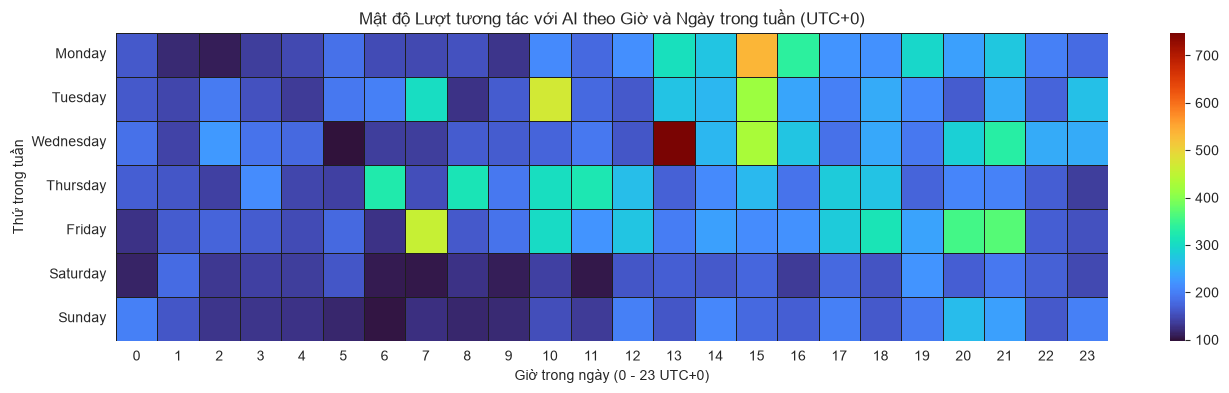

In [46]:
heatmap_data = df_raw.pivot_table(
    index='Day_of_Week',
    columns='Hour',
    values='commit_date',
    aggfunc='count',
    fill_value=0
)

days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = heatmap_data.reindex(days_order)

plt.figure(figsize=(16, 4))
sns.heatmap(heatmap_data, cmap='turbo', linewidths=0.5, linecolor='#1e1e1e')
plt.title('Mật độ Lượt tương tác với AI theo Giờ và Ngày trong tuần (UTC+0)')
plt.xlabel('Giờ trong ngày (0 - 23 UTC+0)')
plt.ylabel('Thứ trong tuần')
plt.show()